# Notebook 4: Why a quality gate matters for a baseline-normalized score

Temple's headline number is described as **baseline-normalized**: it is read relative to
*your own* normal, not as an absolute value. That design has a weakness: a bad reading
hurts twice. It corrupts today's number **and** the baseline it is later compared against.

We can't measure Temple's metric (no data, no ground truth), so this notebook uses a
**stand-in with real ground truth**: heart rate relative to the person's recent baseline.

`index = (heart rate / baseline - 1) x 100`  (% above or below your recent normal)
where `baseline` = median of the previous 10 minutes.

We compute it three ways and compare with the ECG-based "true" index:
1. **True index:** ECG heart rate, ECG baseline (the target).
2. **Ungated:** our PPG estimate for every window, baseline from every window.
3. **Gated:** show an index only in windows the quality model trusts, and build the
   baseline only from those trusted windows.

**This is a heart-rate proxy, not cerebral blood flow.** The point is the mechanism:
gating protects both the reading and the baseline. 

Input: `results/03_window_predictions.csv` from notebook 3. Its `p_good` column holds
out-of-fold predictions (each person was predicted by a model that never saw them).

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "../results"
MAKE_FAKE = False                        # True = read the dry-run output of notebook 3 (../dryrun/results)
if MAKE_FAKE:
    RESULTS_DIR = "../dryrun/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
PRED_CSV = os.path.join(RESULTS_DIR, "03_window_predictions.csv")
SHIFT_S = 2                              # one window every 2 seconds
BASE_MIN = 10                            # baseline = median of the previous 10 minutes
BASE_N = int(BASE_MIN * 60 / SHIFT_S)    # 300 windows
MIN_N = 30                               # need at least 1 minute of accepted readings first
COVERAGE_TARGETS = [1.0, 0.8, 0.7, 0.5]  # share of windows where the device shows a reading

## 1. Load the predictions

In [4]:
assert os.path.exists(PRED_CSV), f"{PRED_CSV} not found. Run notebook 3 first."
df = pd.read_csv(PRED_CSV)
need = ["subject", "window", "activity", "hr_true", "est", "p_good"]
missing = [c for c in need if c not in df.columns]
assert not missing, f"missing columns {missing}; re-run notebook 3 so it saves 03_window_predictions.csv"
df = df.sort_values(["subject", "window"]).reset_index(drop=True)
print(len(df), "windows,", df.subject.nunique(), "subjects")

64697 windows, 15 subjects


## 2. Build the true index and the pipelines
The baseline only looks at **previous** windows (`shift(1)`), as a real device would.

In [5]:
def rolling_base(x):
    return x.shift(1).rolling(BASE_N, min_periods=MIN_N).median()

df["base_true"] = df.groupby("subject")["hr_true"].transform(rolling_base)
df["idx_true"] = (df.hr_true / df.base_true - 1) * 100

def run_pipeline(df, trust_cut):
    accepted = df.p_good >= trust_cut
    est_trusted = df.est.where(accepted)                       # untrusted windows are ignored
    base = est_trusted.groupby(df.subject).transform(rolling_base)
    idx = (df.est / base - 1) * 100
    return idx.where(accepted)                                 # no number shown in untrusted windows

## 3. How far is each pipeline's index from the truth?
Error is in **percentage points** (pp) of the index. We pick the trust cut-off so the
device shows a reading in roughly the target share of windows.

In [6]:
rows, idxs, cuts = [], {}, {}
for cov in COVERAGE_TARGETS:
    cut = -np.inf if cov >= 1 else float(np.quantile(df.p_good, 1 - cov))
    idx = run_pipeline(df, cut)
    idxs[cov], cuts[cov] = idx, cut
    ok = idx.notna() & df.idx_true.notna()
    err = (idx - df.idx_true).abs()
    rows.append({"target coverage": f"{int(cov * 100)}%",
                 "windows with an index": f"{100 * ok.mean():.1f}%",
                 "mean error (pp)": round(err[ok].mean(), 2),
                 "median error (pp)": round(err[ok].median(), 2),
                 "% windows off by >20pp": round(100 * (err[ok] > 20).mean(), 1)})
summary = pd.DataFrame(rows).set_index("target coverage")
print(summary.to_string())
summary.to_csv(os.path.join(RESULTS_DIR, "04_index_error.csv"))

                windows with an index  mean error (pp)  median error (pp)  % windows off by >20pp
target coverage                                                                                  
100%                            99.3%            18.49               9.11                    31.8
80%                             79.3%            10.30               4.61                    15.8
70%                             69.3%             7.61               3.69                     9.6
50%                             48.4%             5.05               2.85                     3.5


## 4. Which activities does gating help?

In [7]:
GATE = 0.7
ok_u = idxs[1.0].notna() & df.idx_true.notna()
ok_g = idxs[GATE].notna() & df.idx_true.notna()
by_act = pd.DataFrame({
    "ungated error (pp)": (idxs[1.0] - df.idx_true).abs()[ok_u].groupby(df.activity[ok_u]).mean(),
    f"gated error (pp)": (idxs[GATE] - df.idx_true).abs()[ok_g].groupby(df.activity[ok_g]).mean(),
    "% of windows still shown": 100 * ok_g.groupby(df.activity).mean()}).round(1)
print(f"Gate keeps about {int(GATE * 100)}% of windows overall:")
print(by_act.to_string())
by_act.to_csv(os.path.join(RESULTS_DIR, "04_index_error_by_activity.csv"))

Gate keeps about 70% of windows overall:
              ungated error (pp)  gated error (pp)  % of windows still shown
activity                                                                    
cycling                     27.0               9.5                      77.1
driving                     13.9               6.1                      75.1
lunch break                 14.9               6.4                      75.3
sitting                      4.8               3.5                      88.4
stairs                      45.8              22.8                      46.7
table soccer                26.0              12.4                      40.9
transient                   21.1               8.7                      58.3
walking                     19.7               8.3                      62.7
working                     13.3               6.5                      84.1


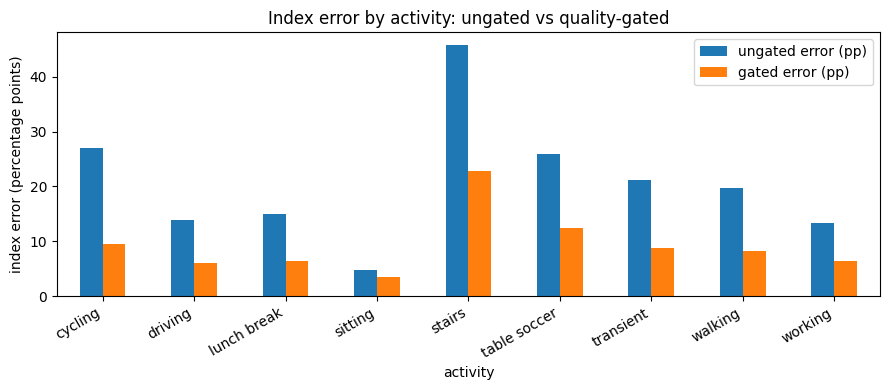

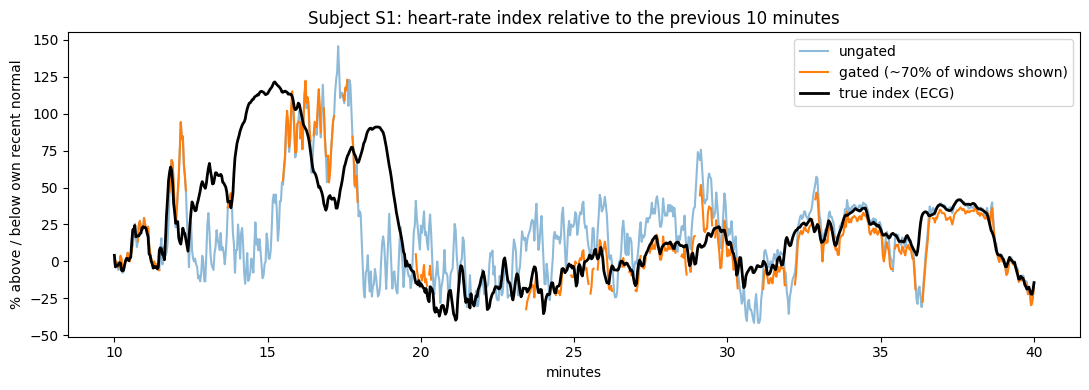

In [8]:
ax = by_act[["ungated error (pp)", "gated error (pp)"]].plot.bar(figsize=(9, 4))
ax.set_ylabel("index error (percentage points)")
ax.set_title("Index error by activity: ungated vs quality-gated")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "04_chart_index_by_activity.png"), dpi=150)
plt.show()

sid0 = int(df.subject.min())
m = (df.subject == sid0) & (df.window * SHIFT_S / 60 >= 10) & (df.window * SHIFT_S / 60 <= 40)
t = df.loc[m, "window"] * SHIFT_S / 60
plt.figure(figsize=(11, 4))
plt.plot(t, idxs[1.0][m], color="tab:blue", alpha=.5, label="ungated")
plt.plot(t, idxs[GATE][m], color="tab:orange", lw=1.5, label=f"gated (~{int(GATE * 100)}% of windows shown)")
plt.plot(t, df.loc[m, "idx_true"], "k", lw=2, label="true index (ECG)", zorder=5)
plt.xlabel("minutes"); plt.ylabel("% above / below own recent normal")
plt.title(f"Subject S{sid0}: heart-rate index relative to the previous 10 minutes")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "04_chart_index_example.png"), dpi=150)
plt.show()